# FID / KID Results

Plot FID and KID bar charts from `inception_distance.py` results.
Set `RESULTS_PATHS` below to choose which result sets to load.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

## Configuration

Map a short label to the path of each `results.json` you want to plot.
Set `DATASETS_TO_PLOT` to restrict which datasets appear (or leave as `None` to plot all).

In [3]:
# ============ CONFIGURATION ============

# Each entry: label -> path to results.json
RESULTS_PATHS = {
    "5000 epochs": "../data/inception_distance_results/260131_141610_437070_23/results.json",
}

# Which datasets to include in the plot.
# Set to None to plot all datasets, or provide a list to filter, e.g.:
# DATASETS_TO_PLOT = ["prior_deterministic_qpos", "prior_predicted_logvar_qpos"]
DATASETS_TO_PLOT = ['prior_logvar_0_qpos', 'prior_logvar_-0.5_qpos', 'prior_logvar_-1qpos', 'prior_logvar_-2_qpos', 'prior_logvar_-3_qpos', 'prior_logvar_-4_qpos', 'prior_deterministic_qpos', 'prior_predicted_logvar_qpos']

# Whether to show the split-baseline reference line
SHOW_SPLIT_BASELINE = True

# Which metric(s) to plot: "fid", "kid", or "both"
METRIC = "both"

## Load Results

In [4]:
results = {}
for label, path in RESULTS_PATHS.items():
    with open(path) as f:
        data = json.load(f)
    results[label] = data
    meta = data["metadata"]
    n_seeds = len(meta["seeds"])
    n_datasets = len(meta["fake_datasets"])
    print(f"{label}:")
    print(f"  Seeds: {meta['seeds']}")
    print(f"  Real dataset: {meta['real_dataset']}")
    print(f"  Fake datasets ({n_datasets}): {meta['fake_datasets']}")
    print(f"  Epochs: {meta['num_epochs']}, Latent dim: {meta['latent_dim']}")
    print()

5000 epochs:
  Seeds: [0, 1, 2, 3]
  Real dataset: encoder_decoder_qpos
  Fake datasets (9): ['original_qpos', 'prior_deterministic_qpos', 'prior_logvar_-0.5_qpos', 'prior_logvar_-1_qpos', 'prior_logvar_-2_qpos', 'prior_logvar_-3_qpos', 'prior_logvar_-4_qpos', 'prior_logvar_0_qpos', 'prior_predicted_logvar_qpos']
  Epochs: 5000, Latent dim: 64



## Helper Functions

In [5]:
def pretty_name(dataset_name: str) -> str:
    """Convert dataset key to a readable label."""
    name = dataset_name.replace("_qpos", "")
    if name.startswith("prior_logvar_"):
        logvar = float(name.replace("prior_logvar_", ""))
        std = np.exp(logvar / 2)
        return f"Prior (std={std:.2f})"
    replacements = {
        "prior_deterministic": "Prior (deterministic)",
        "prior_predicted_logvar": "Prior (predicted logvar)",
        "encoder_decoder": "Encoder-Decoder",
        "original": "Original (MoCap)",
    }
    return replacements.get(name, name)


def get_plot_datasets(aggregated: dict, filter_list: list | None) -> list[str]:
    """Return dataset keys to plot, excluding self/split baselines."""
    skip = {"self_comparison", "split_baseline"}
    datasets = [k for k in aggregated if k not in skip]
    if filter_list is not None:
        datasets = [d for d in datasets if d in filter_list]
    return datasets

## Single-Run Bar Plots

One bar chart per loaded result set.

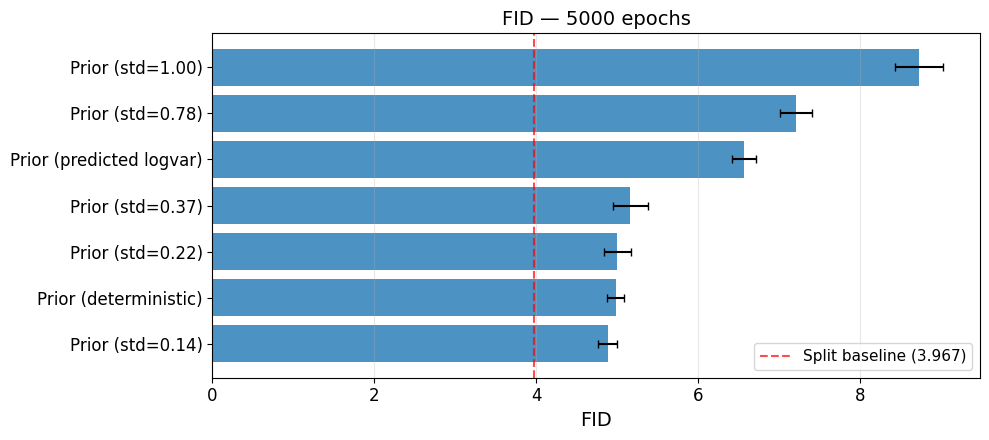

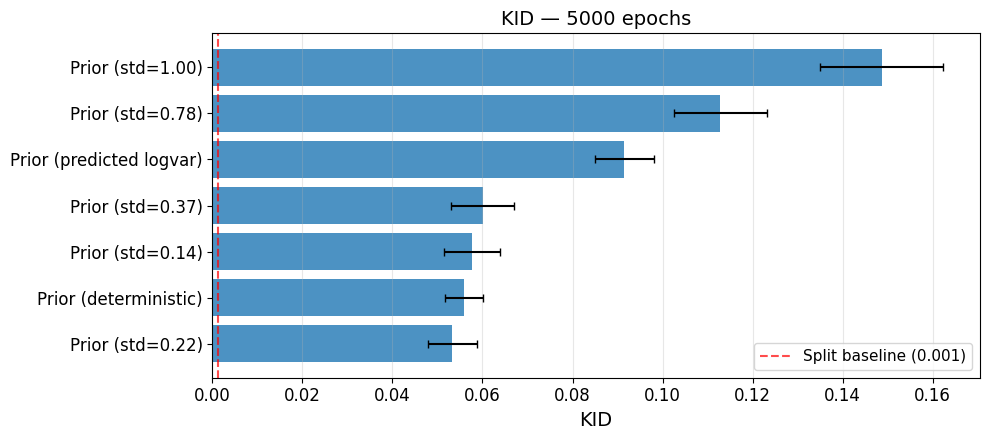

In [6]:
def plot_barplot(
    aggregated: dict,
    metric: str,
    title: str,
    datasets_to_plot: list | None = None,
    show_split_baseline: bool = True,
    ax: plt.Axes | None = None,
) -> plt.Axes:
    """Plot a horizontal bar chart for FID or KID.

    Args:
        aggregated: The 'aggregated' dict from results.json.
        metric: 'fid' or 'kid'.
        title: Plot title.
        datasets_to_plot: List of dataset keys to include, or None for all.
        show_split_baseline: Whether to draw the split-baseline reference line.
        ax: Optional axes to plot on.
    """
    datasets = get_plot_datasets(aggregated, datasets_to_plot)

    # Sort by mean value (ascending)
    datasets.sort(key=lambda d: aggregated[d][f"{metric}_mean"])

    names = [pretty_name(d) for d in datasets]
    means = [aggregated[d][f"{metric}_mean"] for d in datasets]
    stds = [aggregated[d][f"{metric}_std"] for d in datasets]

    if ax is None:
        _, ax = plt.subplots(figsize=(10, max(3, len(names) * 0.5 + 1)))

    y_pos = np.arange(len(names))
    ax.barh(y_pos, means, xerr=stds, align="center", alpha=0.8, capsize=3)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(names, fontsize=12)
    ax.set_xlabel(metric.upper(), fontsize=14)
    ax.set_title(title, fontsize=14)

    if show_split_baseline and "split_baseline" in aggregated:
        ref = aggregated["split_baseline"][f"{metric}_mean"]
        ax.axvline(
            x=ref, color="red", linestyle="--", alpha=0.7,
            label=f"Split baseline ({ref:.3f})",
        )
        ax.legend(fontsize=11)

    ax.grid(True, alpha=0.3, axis="x")
    ax.tick_params(labelsize=12)
    return ax


for label, data in results.items():
    agg = data["aggregated"]
    if METRIC in ("fid", "both"):
        plot_barplot(agg, "fid", f"FID — {label}", DATASETS_TO_PLOT, SHOW_SPLIT_BASELINE)
        plt.tight_layout()
        plt.show()
    if METRIC in ("kid", "both"):
        plot_barplot(agg, "kid", f"KID — {label}", DATASETS_TO_PLOT, SHOW_SPLIT_BASELINE)
        plt.tight_layout()
        plt.show()

## Per-Seed Distribution

Show per-seed FID/KID values as a scatter overlay on the bar chart to
visualize variance across VAE training seeds.

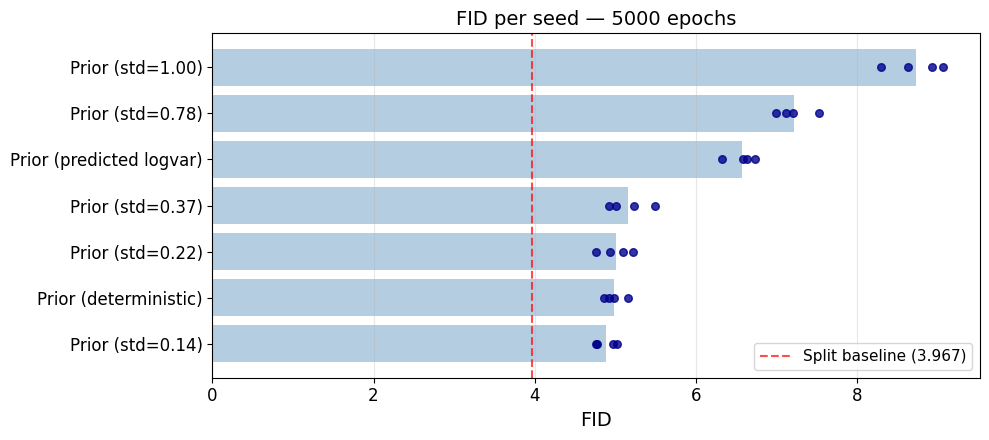

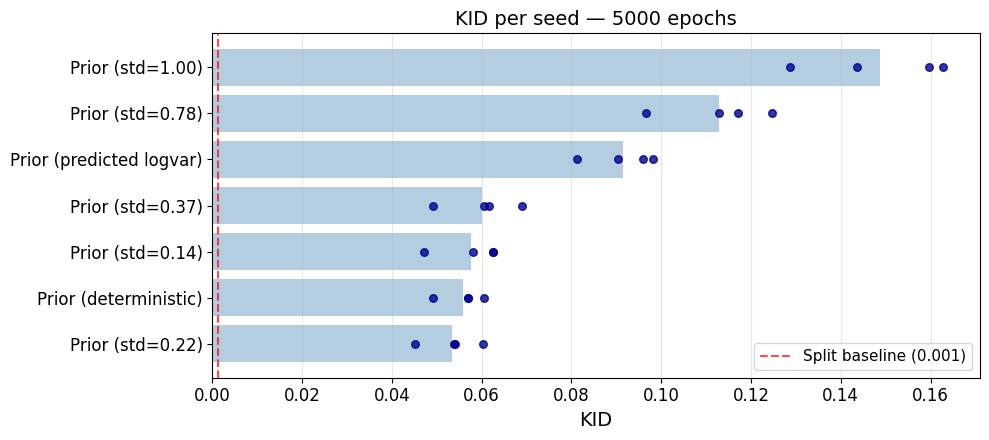

In [7]:
def plot_per_seed(
    data: dict,
    metric: str,
    title: str,
    datasets_to_plot: list | None = None,
    show_split_baseline: bool = True,
):
    """Bar chart with individual seed values overlaid as dots."""
    agg = data["aggregated"]
    per_seed = data["per_seed_results"]
    datasets = get_plot_datasets(agg, datasets_to_plot)

    # Sort by mean
    datasets.sort(key=lambda d: agg[d][f"{metric}_mean"])
    names = [pretty_name(d) for d in datasets]
    means = [agg[d][f"{metric}_mean"] for d in datasets]

    fig, ax = plt.subplots(figsize=(10, max(3, len(names) * 0.5 + 1)))
    y_pos = np.arange(len(names))

    ax.barh(y_pos, means, align="center", alpha=0.4, color="steelblue")

    # Overlay individual seed values
    metric_key = "fid" if metric == "fid" else "kid_mean"
    for i, ds in enumerate(datasets):
        seed_vals = [sr["datasets"][ds][metric_key] for sr in per_seed]
        ax.scatter(
            seed_vals, [i] * len(seed_vals),
            color="darkblue", zorder=3, s=30, alpha=0.8,
        )

    ax.set_yticks(y_pos)
    ax.set_yticklabels(names, fontsize=12)
    ax.set_xlabel(metric.upper(), fontsize=14)
    ax.set_title(title, fontsize=14)

    if show_split_baseline and "split_baseline" in agg:
        ref = agg["split_baseline"][f"{metric}_mean"]
        ax.axvline(
            x=ref, color="red", linestyle="--", alpha=0.7,
            label=f"Split baseline ({ref:.3f})",
        )
        ax.legend(fontsize=11)

    ax.grid(True, alpha=0.3, axis="x")
    ax.tick_params(labelsize=12)
    plt.tight_layout()
    plt.show()


for label, data in results.items():
    if METRIC in ("fid", "both"):
        plot_per_seed(data, "fid", f"FID per seed — {label}", DATASETS_TO_PLOT, SHOW_SPLIT_BASELINE)
    if METRIC in ("kid", "both"):
        plot_per_seed(data, "kid", f"KID per seed — {label}", DATASETS_TO_PLOT, SHOW_SPLIT_BASELINE)

## Multi-Run Comparison

If multiple result sets are loaded, show them side-by-side for each dataset.

In [8]:
if len(results) > 1:
    # Find common datasets across all runs
    all_dataset_sets = [
        set(get_plot_datasets(d["aggregated"], DATASETS_TO_PLOT))
        for d in results.values()
    ]
    common_datasets = sorted(set.intersection(*all_dataset_sets))

    for metric in (["fid", "kid"] if METRIC == "both" else [METRIC]):
        # Sort by mean of first run
        first_agg = list(results.values())[0]["aggregated"]
        common_datasets.sort(key=lambda d: first_agg[d][f"{metric}_mean"])
        names = [pretty_name(d) for d in common_datasets]

        fig, ax = plt.subplots(figsize=(12, max(3, len(names) * 0.6 + 1)))
        n_runs = len(results)
        bar_height = 0.8 / n_runs
        colors = plt.cm.Set2(np.linspace(0, 1, n_runs))

        for run_idx, (run_label, data) in enumerate(results.items()):
            agg = data["aggregated"]
            means = [agg[d][f"{metric}_mean"] for d in common_datasets]
            stds = [agg[d][f"{metric}_std"] for d in common_datasets]
            y_offsets = np.arange(len(common_datasets)) + (run_idx - n_runs / 2 + 0.5) * bar_height

            ax.barh(
                y_offsets, means, height=bar_height, xerr=stds,
                align="center", alpha=0.8, capsize=2, color=colors[run_idx],
                label=run_label,
            )

        ax.set_yticks(np.arange(len(names)))
        ax.set_yticklabels(names, fontsize=12)
        ax.set_xlabel(metric.upper(), fontsize=14)
        ax.set_title(f"{metric.upper()} Comparison", fontsize=14)
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3, axis="x")
        ax.tick_params(labelsize=12)
        plt.tight_layout()
        plt.show()
else:
    print("Only one result set loaded — add more to RESULTS_PATHS for comparison.")

Only one result set loaded — add more to RESULTS_PATHS for comparison.


## Summary Table

In [9]:
for label, data in results.items():
    agg = data["aggregated"]
    datasets = get_plot_datasets(agg, DATASETS_TO_PLOT)
    datasets.sort(key=lambda d: agg[d]["fid_mean"])

    print(f"{'=' * 80}")
    print(f"  {label}")
    print(f"{'=' * 80}")
    print(f"{'Dataset':<28} {'FID':>16} {'KID':>20}")
    print(f"{'-' * 80}")
    if "split_baseline" in agg:
        sb = agg["split_baseline"]
        print(
            f"{'[split baseline]':<28} "
            f"{sb['fid_mean']:>7.3f} +/- {sb['fid_std']:<6.3f} "
            f"{sb['kid_mean']:>9.5f} +/- {sb['kid_std']:<8.5f}"
        )
    for d in datasets:
        v = agg[d]
        print(
            f"{pretty_name(d):<28} "
            f"{v['fid_mean']:>7.3f} +/- {v['fid_std']:<6.3f} "
            f"{v['kid_mean']:>9.5f} +/- {v['kid_std']:<8.5f}"
        )
    print()

  5000 epochs
Dataset                                   FID                  KID
--------------------------------------------------------------------------------
[split baseline]               3.967 +/- 0.015    0.00119 +/- 0.00070 
Prior (std=0.14)               4.882 +/- 0.119    0.05762 +/- 0.00626 
Prior (deterministic)          4.980 +/- 0.109    0.05588 +/- 0.00418 
Prior (std=0.22)               5.002 +/- 0.171    0.05329 +/- 0.00542 
Prior (std=0.37)               5.162 +/- 0.220    0.06004 +/- 0.00703 
Prior (predicted logvar)       6.567 +/- 0.148    0.09149 +/- 0.00652 
Prior (std=0.78)               7.211 +/- 0.194    0.11282 +/- 0.01031 
Prior (std=1.00)               8.731 +/- 0.299    0.14870 +/- 0.01367 

